# Member 3 — Assembled housing/transport integration notebook

**NYC affordable-housing activity and investigated serious crashes**  
Frozen source retrieval: 9 November 2026. Primary common full years: **2022–2025**.  
This notebook is an executed, reproducible handoff for the requested Member 2/3 scopes. Read the saved outputs or rerun every cell after extracting the whole package. The team-wide milestone still needs Member 1/4's research additions and Member 4's website/deployment. Assigned roles are not assertions of independent authorship.

**Story:** Where housing activity and serious-crash investigations occur together, do their distributions, composition and trajectories align? Planners need evidence across agencies, but these data support descriptive screening, not causal claims or resident-level risk estimates.

## 1. Sources, provenance and feasibility

Exactly two sources, both already selected in the supplied Member 1 notebook:

| Domain | Catalog | Official source | Raw shape | Useful attributes |
|---|---|---|---|---|
| Housing | H2 | [Affordable Housing Production by Building](https://data.cityofnewyork.us/d/hg8x-zxpr) | 9,551 × 41 | Borough, Postcode, Project Start Date, Building ID, construction type, counted units |
| Transport | T4 | [SIRTA](https://data.cityofnewyork.us/d/xeqp-qz8h) | 13,754 × 23 | Crash Borough, ZipCode, Crash Date, collision ID, severe injuries, fatalities |

Both exceed the required nine columns. They are in the recommended catalog, so no outside-catalog approval/feasibility claim is needed. Full source snapshots are small enough to keep all records: **no sampling**. The API query limit of 20,000 exceeds separately verified row counts. API fields are lowercase underscore names; official field mappings are bundled. CSV export calls initially failed, so the full JSON API responses were converted to CSV without cleaning source values. The raw snapshots and checksums make the analysis reproducible even if the live source changes.

SIRTA covers serious vehicular crashes investigated/analyzed by NYC DOT. **It is not all NYC crashes and does not measure transit access.** HPD counted units include preservation and new construction; a project-start year does not imply a completed/occupied new home. No additional dataset is introduced.

In [1]:
from pathlib import Path
import sys, json, inspect
import pandas as pd
from IPython.display import display, Image, Markdown, Code
ROOT = Path.cwd()
if not (ROOT / "pipeline.py").exists() and (ROOT.parent / "pipeline.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "pipeline.py").exists():
    raise RuntimeError("Extract the whole ZIP and run from its root or notebooks folder.")
sys.path.insert(0, str(ROOT))
from pipeline import (run, clean_transport, clean_housing, housing_aggregate,
                      transport_aggregate, integrate, PRIMARY_YEARS)
from charts import make_charts
from validate import validate
frames, audit = run(ROOT)
findings = make_charts(frames, ROOT)
raw_housing = pd.read_csv(ROOT / "data/raw/housing_raw.csv", dtype="string")
raw_transport = pd.read_csv(ROOT / "data/raw/transport_raw.csv", dtype="string")
housing = frames["housing_clean"]
transport = frames["transport_clean"]
print("Loaded frozen full snapshots; preprocessing and charts rebuilt offline.")

Loaded frozen full snapshots; preprocessing and charts rebuilt offline.


In [2]:
manifest = json.loads((ROOT / "data/raw/source_manifest.json").read_text())
display(pd.DataFrame([{k:v for k,v in record.items() if k in ["dataset_id","title","retrieved_utc","verified_api_row_count","source_rows_updated_utc","sha256"]} for record in manifest.values()]))
display(pd.DataFrame({"dataset":["housing","transport"],"rows":[len(raw_housing),len(raw_transport)],"columns":[raw_housing.shape[1],raw_transport.shape[1]]}))
display(raw_transport.head(3))

,dataset_id,title,retrieved_utc,verified_api_row_count,source_rows_updated_utc,sha256
0,hg8x-zxpr,Affordable Housing Production by Building,2026-11-09T16:39:18.458092+00:00,9551,2026-09-30T19:21:51+00:00,01ed5d1450933bdaccc31994ccb2f3baa7ff048be4149c...
1,xeqp-qz8h,"Serious Injury Response, Tracking & Analysis P...",2026-11-09T16:39:14.776629+00:00,13754,2026-10-09T16:45:57+00:00,c6c94d029ea5f4ba1d706c9004fe04372aa0cab7289d92...


,dataset,rows,columns
0,housing,9551,41
1,transport,13754,23


,open_data_crash_id,crash_date,crash_time,crash_police_precinct,crash_borough,total_non_severe_injuries,total_severe_injuries,total_fatalities,latitude,longitude,...,similar_fatalities_all,address,community_board,council_district,bin,bbl,census_tract_2020_,neighborhood_tabulation_area_nta_2020_,highway_reference_marker,zipcode
0,4492364,2022-01-01T00:00:00.000,01:28,46,Bronx,1,1,0,40.8587070,-73.9037000,...,1,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,4491159,2022-01-01T00:00:00.000,04:33,46,Bronx,0,1,0,<NA>,<NA>,...,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,4491487,2022-01-01T00:00:00.000,05:55,47,Bronx,0,1,0,40.8715500,-73.8642800,...,0,3207 WALLACE AVENUE,212,12,2056281,2045980025,372,BX1201,<NA>,<NA>


## 2. What Member 1 supplied and what changed

The original six-cell notebook is preserved unchanged under `references/`. It chose H2/T4, removed exact duplicates, parsed dates, normalized housing ZIP, flagged total-unit outliers and exported a ZIP/start-year housing aggregate. Saved original results match the source sizes and the 1,171 housing IQR flags. Its exported CSV was not in the supplied ZIP.

This handoff keeps the source choice and start-year interpretation. It adds full EDA/narrative, explicit unknown-value policies, clean transport aggregation and integration. It counts source housing **records** separately from unique Building IDs. It keeps ZIP-missing records for borough analysis and replaces substring ZIP extraction with whole-value validation. Strict sums preserve unknown counts. The supplied work has no research questions/charts or prompt history; those gaps remain disclosed rather than attributed to Member 1. `REVIEW_AND_DECISIONS.md` contains the full review.

## 3. Transportation EDA before cleaning

Inspect dimensions, fields, missingness, categories and descriptive numeric statistics before deciding what to discard. Source numbers are read as text to preserve identifiers; only measurement columns are converted. Initial missingness includes undated placeholder-like rows, so compare it with post-cleaning geography coverage later.

In [3]:
display(pd.DataFrame({"field":raw_transport.columns,"dtype":raw_transport.dtypes.astype(str).values,"missing":raw_transport.isna().sum().values,"missing_pct":(100*raw_transport.isna().mean()).round(2).values}))
display(raw_transport["crash_borough"].value_counts(dropna=False).rename_axis("source_borough").to_frame("records"))
display(raw_transport[["total_non_severe_injuries","total_severe_injuries","total_fatalities"]].apply(pd.to_numeric,errors="coerce").describe())
print("Exact duplicate rows:", raw_transport.duplicated().sum())
print("Repeated non-null collision IDs:", raw_transport["open_data_crash_id"].dropna().duplicated().sum())

,field,dtype,missing,missing_pct
0,open_data_crash_id,string,444,3.23
1,crash_date,string,444,3.23
2,crash_time,string,444,3.23
3,crash_police_precinct,string,444,3.23
4,crash_borough,string,499,3.63
5,total_non_severe_injuries,string,444,3.23
6,total_severe_injuries,string,444,3.23
7,total_fatalities,string,444,3.23
8,latitude,string,2886,20.98
9,longitude,string,2886,20.98


,records
source_borough,
Brooklyn,3954
Queens,3282
Manhattan,2733
Bronx,2617
Staten Island,669
<NA>,499


,total_non_severe_injuries,total_severe_injuries,total_fatalities
count,13310.0,13310.0,13310.0
mean,0.270473,1.011495,0.082795
std,0.836031,0.451514,0.294304
min,0.0,0.0,0.0
25%,0.0,1.0,0.0
50%,0.0,1.0,0.0
75%,0.0,1.0,0.0
max,19.0,7.0,5.0


Exact duplicate rows: 3
Repeated non-null collision IDs: 1


## 4. Transportation pre-integration cleaning

1. Remove only exact duplicate rows, retaining source row numbers for traceability.
2. Trim whitespace, normalize borough strings and validate the whole ZIP value; keep geographic identifiers as strings. Missing ZIP/borough is not guessed from another record or address.
3. Coerce dates and quarantine undated/invalid events. Both remaining rows for conflicting collision ID **4597666** are quarantined: they differ in year/fatalities, so choosing one would fabricate certainty.
4. Convert injury/fatality measurements to nonnegative nullable integers. Invalid or unknown values stay unknown. Derive severity with explicit missingness propagation.
5. Flag severity IQR outliers and retain plausible rare events. The IQR collapses at one, so this is a review flag, not grounds to remove multi-victim events. Coordinates outside a broad NYC domain become unknown without affecting the borough join.
6. Keep missing-geography records in `transport_clean`; omit them only from aggregates requiring that geographic key. Quarantine records and reasons are exported separately.

The code below is the actual cleaner executed by this notebook, not pseudocode.

In [4]:
display(Code(inspect.getsource(clean_transport), language="python"))

def clean_transport(raw):
    audit = {'input_rows': len(raw), 'input_columns': len(raw.columns)}
    d = raw.drop_duplicates().copy()
    audit['exact_duplicates_removed'] = len(raw)-len(d)
    d['source_row'] = d.index + 2                                   
    for c in d.select_dtypes(include=['object','string']).columns:
        d[c] = text(d[c])
    d['collision_id'] = text(d['open_data_crash_id']).str.replace(r'\.0+$','',regex=True)
    d['crash_date'] = pd.to_datetime(d['crash_date'], errors='coerce')
    d['year'] = d['crash_date'].dt.year.astype('Int64')
    d['borough'] = borough(d['crash_borough'])
    d['zip'] = standard_zip(d['zipcode'])
    audit['invalid_numeric_counts'] = {}
    for c in ['total_non_severe_injuries','total_severe_injuries','total_fatalities']:
        orig = d[c].copy()
        d[c] = nonnegative_integer(d[c])
        audit['invalid_numeric_counts'][c] = int((orig.notna() & d[c].isna()).sum())
                                                                                
    d['severe_or_fatal'] = d['total_severe_injuries'] + d['total_fatalities']
    d['severity'] = pd.Series('UNKNOWN', index=d.index, dtype='string')
    d.loc[d['total_fatalities'].gt(0).fillna(False), 'severity'] = 'FATAL'
    known_nonfatal = d['total_fatalities'].eq(0).fillna(False)
    d.loc[(known_nonfatal & d['total_severe_injuries'].gt(0)).fillna(False),'severity'] = 'SEVERE_NONFATAL'
    d.loc[(known_nonfatal & d['total_severe_injuries'].eq(0)).fillna(False),'severity'] = 'NO_RECORDED_SEVERE_OR_FATAL'
    d['severity_outlier'], audit['severity_iqr'] = iqr_flags(d['severe_or_fatal'])
    for c, low, high in [('latitude',40.4,41.0),('longitude',-74.3,-73.65)]:
        if c in d:
            n = pd.to_numeric(d[c],errors='coerce')
            d[c+'_invalid'] = n.notna() & ~n.between(low,high)
            d[c] = n.where(n.between(low,high))
                                                                                   
    conflict = d['collision_id'].notna() & d['collision_id'].duplicated(keep=False)
    reasons = pd.Series('', index=d.index, dtype='string')
    for mask, label in [(conflict,'conflicting_collision_id;'),(d['crash_date'].isna(),'missing_or_invalid_date;'),
                        (d['year'].notna() & ~d['year'].between(2022,2026),'out_of_scope_year;')]:
        reasons.loc[mask] = reasons.loc[mask] + label
    excluded = d.loc[reasons.ne('')].copy()
    excluded['exclusion_reason'] = reasons[reasons.ne('')]
    d = d.loc[reasons.eq('')].copy()
    audit.update(conflicting_id_rows=int(conflict.sum()), excluded_rows=len(excluded), clean_rows=len(d),
                 missing_borough=int(d['borough'].isna().sum()), missing_zip=int(d['zip'].isna().sum()),
                 missing_collision_id=int(d['collision_id'].isna().sum()), severity_outliers=int(d['severity_outlier'].sum()))
    return d, excluded, audit

In [5]:
display(pd.Series(audit["transport"],name="transport_cleaning_audit").to_frame())
display(frames["transport_quarantine"][["source_row","collision_id","crash_date","exclusion_reason"]].head(8))
display(transport["severity"].value_counts().to_frame("records"))
display(transport.loc[transport["severity_outlier"],["collision_id","crash_date","total_severe_injuries","total_fatalities","severity_outlier"]].head(10))
display(transport[["total_non_severe_injuries","total_severe_injuries","total_fatalities","severe_or_fatal"]].describe())

,transport_cleaning_audit
input_rows,13754
input_columns,23
exact_duplicates_removed,3
invalid_numeric_counts,"{'total_non_severe_injuries': 0, 'total_severe..."
severity_iqr,"{'lower': 1.0, 'upper': 1.0, 'q1': 1.0, 'q3': ..."
conflicting_id_rows,2
excluded_rows,443
clean_rows,13308
missing_borough,55
missing_zip,5280


,source_row,collision_id,crash_date,exclusion_reason
46,48,<NA>,NaT,missing_or_invalid_date;
327,329,<NA>,NaT,missing_or_invalid_date;
420,422,<NA>,NaT,missing_or_invalid_date;
1220,1222,<NA>,NaT,missing_or_invalid_date;
1405,1407,<NA>,NaT,missing_or_invalid_date;
1685,1687,<NA>,NaT,missing_or_invalid_date;
1778,1780,<NA>,NaT,missing_or_invalid_date;
1872,1874,<NA>,NaT,missing_or_invalid_date;


,records
severity,
SEVERE_NONFATAL,12262
FATAL,1046


,collision_id,crash_date,total_severe_injuries,total_fatalities,severity_outlier
12,4492669,2022-01-05,3,0,True
22,4495838,2022-01-19,2,0,True
80,4505688,2022-02-25,2,2,True
88,4506607,2022-03-01,3,0,True
89,4506945,2022-03-02,2,0,True
124,4514202,2022-03-26,2,0,True
131,4491817,2022-01-04,1,1,True
132,4492477,2022-01-04,2,0,True
133,4492006,2022-01-04,2,0,True
140,4497887,2022-01-09,2,0,True


,total_non_severe_injuries,total_severe_injuries,total_fatalities,severe_or_fatal
count,13308.0,13308.0,13308.0,13308.0
mean,0.270514,1.011497,0.082732,1.094229
std,0.836087,0.451548,0.294218,0.385527
min,0.0,0.0,0.0,1.0
25%,0.0,1.0,0.0,1.0
50%,0.0,1.0,0.0,1.0
75%,0.0,1.0,0.0,1.0
max,19.0,7.0,5.0,7.0


**Observed cleaning result:** 13,754 raw rows − 3 exact duplicates − 443 quarantined rows = **13,308 clean dated records**. Quarantine includes 441 missing/invalid dates and the two conflicting-ID versions. Fifty-five clean records lack usable borough; 5,280 lack usable ZIP. The 958 IQR flags are retained. No observed count values violate the nonnegative-integer domain rule. Source category normalization and date conversion are visible in the clean table and dtype outputs.

## 5. Housing EDA and shared integration bridge

Housing is preserved as project/building records with Building IDs as text. We do not deduplicate by Building ID alone because the same building can legitimately appear in different projects/years. Repeated complete project/building keys are checked separately. Missing optional bedroom/income counts and completion dates remain unknown; they do not invalidate an otherwise usable start-year record. Five completion-before-start records are flagged and retained, because no duration metric is used.

Total-unit IQR bounds are −60 and 108. The 1,171 flagged records are plausible large properties, so they remain visible rather than being removed to make the distribution look normal. Unknown counted units are never replaced with total building units: those fields mean different things.

In [6]:
display(raw_housing.head(3))
display(pd.DataFrame({"missing":raw_housing.isna().sum(),"missing_pct":(100*raw_housing.isna().mean()).round(2)}))
display(raw_housing[["total_units","all_counted_units"]].apply(pd.to_numeric,errors="coerce").describe())
display(housing["construction_type"].value_counts().to_frame("records"))
display(Code(inspect.getsource(clean_housing), language="python"))
display(pd.Series(audit["housing"],name="housing_cleaning_audit").to_frame())

,project_id,project_name,project_start_date,building_id,house_number,street_name,borough,postcode,bbl,bin,...,_3_br_units,project_completion_date,building_completion_date,moderate_income_units,counted_homeownership_units,middle_income_units,unknown_br_units,_4_br_units,_5_br_units,_6_br_units
0,68872,177-06 WEXFORD TERRACE,2026-06-30T00:00:00.000,991637,177-06,WEXFORD TERRACE,Queens,11432,4098350023,4000000,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,72436,ST. NICK'S. 819 GRAND STREET,2026-06-30T00:00:00.000,1021347,819,GRAND STREET,Brooklyn,11211,3029220001,3070436,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,21199,127,EDGECOMBE AVENUE,Manhattan,10030,1020480037,1060911,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


,missing,missing_pct
project_id,0,0.00
project_name,0,0.00
project_start_date,0,0.00
building_id,1949,20.41
house_number,0,0.00
street_name,0,0.00
borough,0,0.00
postcode,1958,20.50
bbl,2021,21.16
bin,2021,21.16


,total_units,all_counted_units
count,9551.0,9522.0
mean,46.653544,33.705734
std,92.482144,65.834105
min,1.0,1.0
25%,3.0,2.0
50%,12.0,8.0
75%,45.0,30.0
max,1320.0,917.0


,records
construction_type,
PRESERVATION,4785
NEW CONSTRUCTION,4766


def clean_housing(raw):
    audit = {'input_rows': len(raw), 'input_columns': len(raw.columns), 'exact_duplicates_removed': int(raw.duplicated().sum())}
    d = raw.drop_duplicates().copy()
    d['source_row'] = d.index+2
    for c in d.select_dtypes(include=['object','string']).columns:
        d[c] = text(d[c])
    for c in ['project_start_date','project_completion_date','building_completion_date']:
        d[c] = pd.to_datetime(d[c], errors='coerce')
    for c in ['project_id','building_id','bin','bbl']:
        d[c] = text(d[c]).str.replace(r'\.0+$','',regex=True)
    d['borough'] = borough(d['borough'])
    d['zip'] = standard_zip(d['postcode'])
    d['year'] = d['project_start_date'].dt.year.astype('Int64')
    unit_cols = [c for c in d if c.endswith('_units')]
    audit['invalid_numeric_counts'] = {}
    for c in unit_cols:
        orig = d[c].copy(); d[c] = nonnegative_integer(d[c])
        audit['invalid_numeric_counts'][c] = int((orig.notna() & d[c].isna()).sum())
    d['construction_type'] = text(d['reporting_construction_type']).str.upper().fillna('UNKNOWN')
    d['units_outlier'],audit['total_units_iqr'] = iqr_flags(d['total_units'])
    d['counted_exceeds_total'] = (d['all_counted_units'] > d['total_units']).fillna(False)
    d['completion_before_start'] = (d['project_completion_date'] < d['project_start_date']).fillna(False)
                                                                                   
                                                                                   
    business_key = ['project_id','building_id']
    possible_conflict = d[business_key].notna().all(axis=1) & d.duplicated(business_key, keep=False)
    d['repeated_project_building_key'] = possible_conflict
    reasons = pd.Series('', index=d.index,dtype='string')
    for mask,label in [(d['project_start_date'].isna(),'missing_or_invalid_start_date;'),
                        (d['year'].notna() & ~d['year'].between(2014,2026),'out_of_scope_year;'),
                        (possible_conflict,'conflicting_project_building_key;')]:
        reasons.loc[mask] = reasons.loc[mask]+label
    excluded=d.loc[reasons.ne('')].copy();excluded['exclusion_reason']=reasons[reasons.ne('')]
    d=d.loc[reasons.eq('')].copy()
    audit.update(clean_rows=len(d),excluded_rows=len(excluded),missing_zip=int(d['zip'].isna().sum()),
                 missing_borough=int(d['borough'].isna().sum()),unit_outliers=int(d['units_outlier'].sum()),
                 counted_exceeds_total=int(d['counted_exceeds_total'].sum()), completion_before_start=int(d['completion_before_start'].sum()))
    return d, excluded, audit

,housing_cleaning_audit
input_rows,9551
input_columns,41
exact_duplicates_removed,0
invalid_numeric_counts,"{'low_income_units': 0, '_1_br_units': 0, 'cou..."
total_units_iqr,"{'lower': -60.0, 'upper': 108.0, 'q1': 3.0, 'q..."
clean_rows,9551
excluded_rows,0
missing_zip,1958
missing_borough,0
unit_outliers,1171


In [7]:
display(housing.loc[housing["completion_before_start"],["project_id","building_id","project_start_date","project_completion_date","completion_before_start"]])
display(housing.loc[housing["units_outlier"],["project_id","building_id","total_units","units_outlier"]].sort_values("total_units",ascending=False).head(10))
print("Housing counted-unit values missing:", housing["all_counted_units"].isna().sum())
display(housing[["project_id","building_id","borough","zip","year","total_units","all_counted_units"]].dtypes.to_frame("clean_dtype"))

,project_id,building_id,project_start_date,project_completion_date,completion_before_start
1340,76576,<NA>,2025-02-27,2025-02-21,True
3758,76628,1000330,2022-02-17,2021-09-30,True
4714,70377,<NA>,2020-10-29,2020-10-09,True
6422,61837,42889,2018-06-25,2018-06-19,True
6423,61837,43012,2018-06-25,2018-06-19,True


,project_id,building_id,total_units,units_outlier
1442,76349,7514,1320,True
6902,66058,946595,1175,True
9157,49709,946595,1175,True
4533,70840,966785,1122,True
3406,71573,1004938,1046,True
9040,52241,977581,1028,True
6687,65125,44047,1000,True
8451,59538,967059,974,True
4419,72274,1000444,958,True
1781,76312,982497,938,True


Housing counted-unit values missing: 29


,clean_dtype
project_id,string[python]
building_id,string[python]
borough,string[python]
zip,string[python]
year,Int64
total_units,Int64
all_counted_units,Int64


## 6. Geography coverage and outlier understanding

ZIP coverage is strongly time-dependent. The clean 2022 transport records have only **16.26%** usable ZIP coverage; even later years are incomplete. A ZIP-only main analysis would select a changing subset. Borough preserves much more information. No external borough/ZIP lookup is added; ambiguous cross-borough ZIP labels are explicitly excluded from the secondary research analysis.

The histogram uses a log record-count axis to expose rare large events. The two EDA figures below support cleaning decisions and are **additional to**, not replacements for, the research charts.

,dataset,year,records,with_borough,with_zip,zip_coverage_pct
8,housing,2022,670,670,469,70.00
9,housing,2023,872,872,716,82.11
10,housing,2024,868,868,718,82.72
11,housing,2025,854,854,652,76.35
12,housing,2026,539,539,393,72.91
13,transport,2022,2879,2879,468,16.26
14,transport,2023,3015,3015,2052,68.06
15,transport,2024,3116,3114,2179,69.93
16,transport,2025,2947,2913,2336,79.27
17,transport,2026,1351,1332,993,73.50


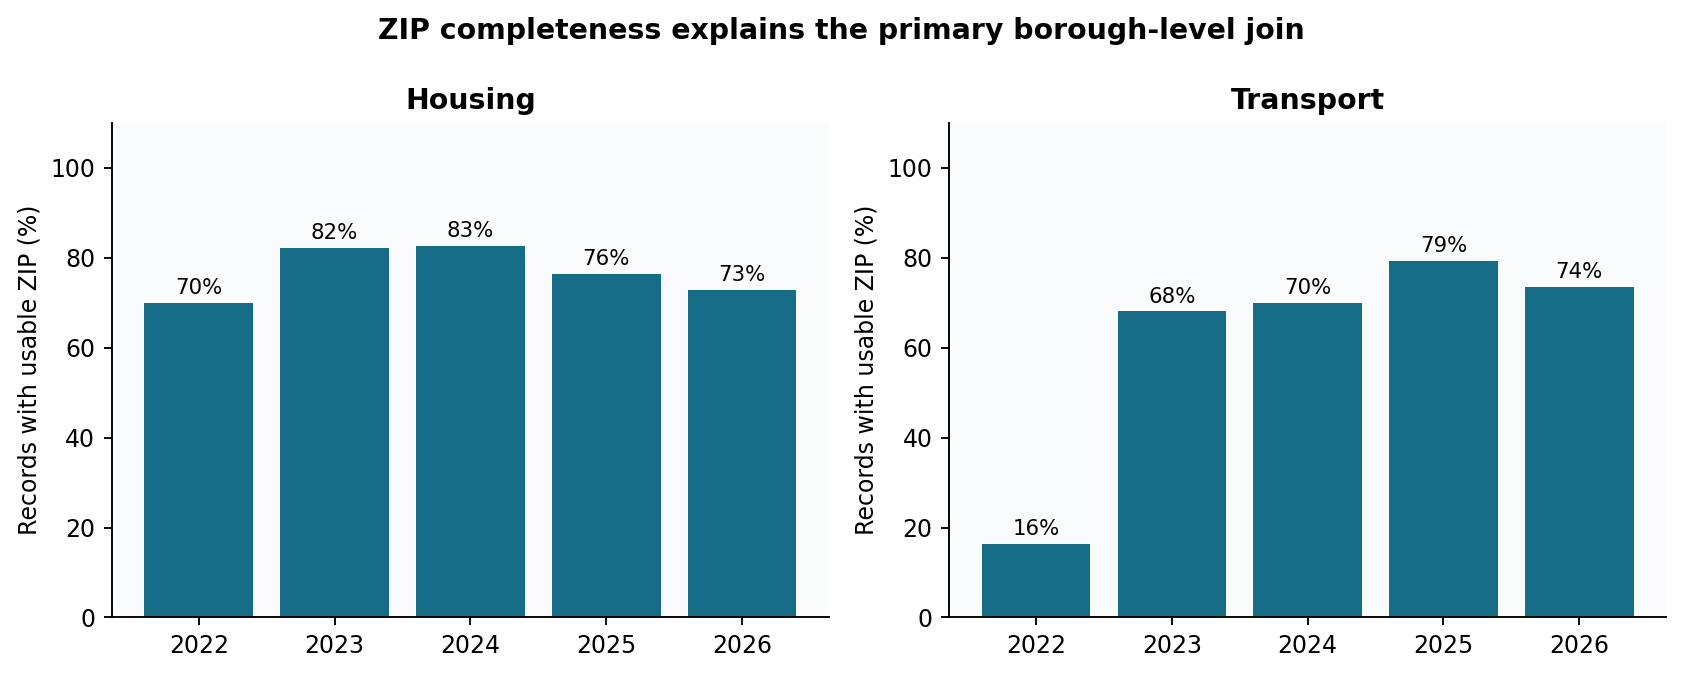

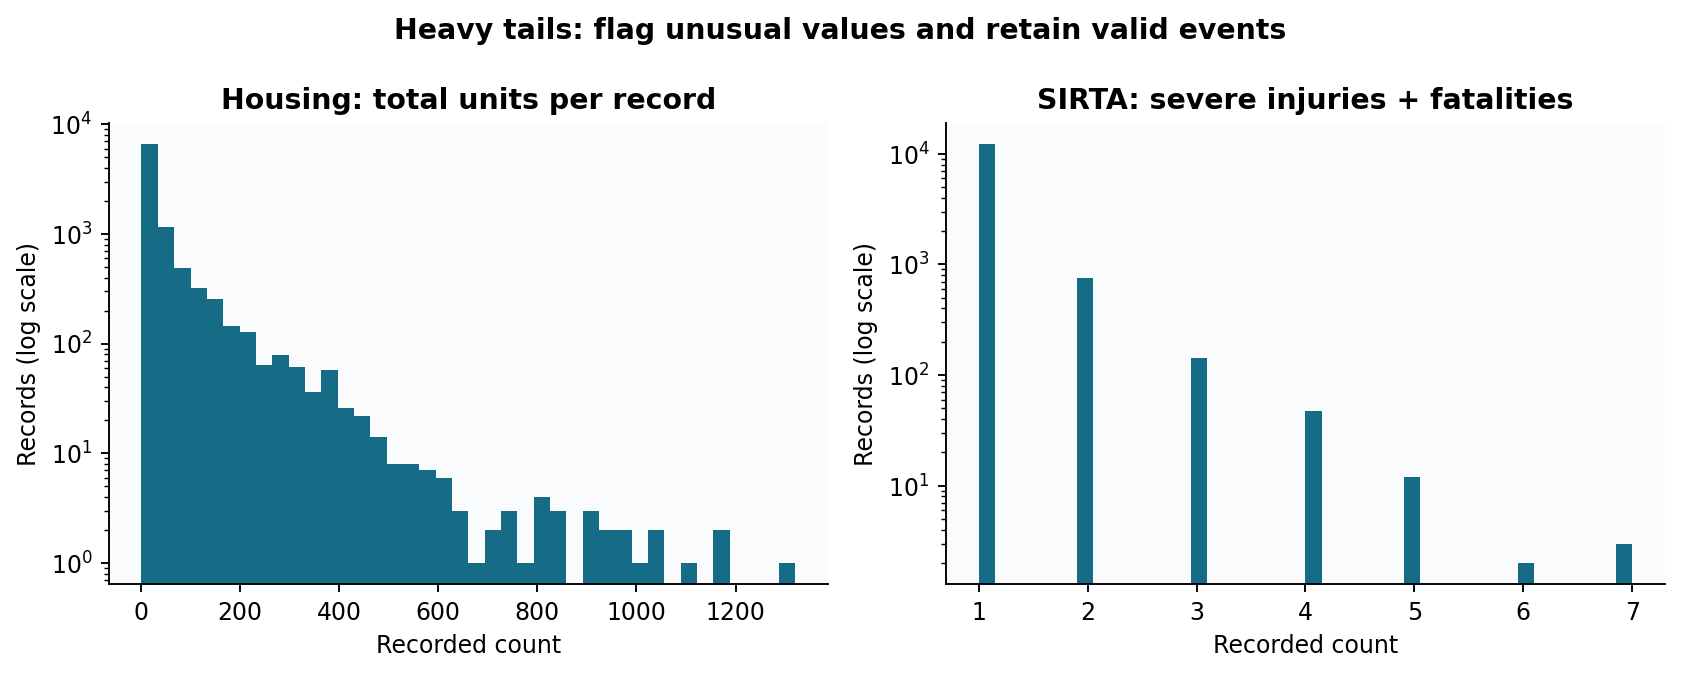

In [8]:
coverage = pd.read_csv(ROOT / "reports/geographic_coverage.csv")
display(coverage.loc[coverage["year"].ge(2022)])
display(Image(filename=str(ROOT / "charts/EDA_zip_completeness.png")))
display(Image(filename=str(ROOT / "charts/EDA_numeric_distributions.png")))

## 7. Integration key, granularity and aggregation

**Primary:** borough × calendar year. Housing year comes from Project Start Date, transport year from Crash Date. The common full-year window is 2022–2025. 2026 is retained in data but excluded because the source dates stop on 30 June. Historic housing years 2014–2021 remain unmatched coverage, not zero-crash years.

Alternatives considered: row-level ZIP joining would multiply unrelated building/crash records; a sole ZIP/year join would discard most 2022 transport data. Borough/year avoids those problems at the cost of just 20 main comparison cells and coarse geography. This is the handoff's documented engineering decision; it does not claim an unrecorded team meeting or approval from the absent members.

Housing aggregates record count, distinct buildings, strict units and known subtotals. Transport aggregates event-record counts, injury/fatality people and known-value coverage. **Both sides are aggregated before joining**. Category tables retain housing construction type and transport severity for the future website; no individual crash is linked to a housing building.

Strict sums become unknown if any contributing value is missing. Known-only subtotals are separate fields so a missing value cannot silently become zero. This conservative policy makes two main housing totals incomplete; chart handling is explained separately.

In [9]:
display(Code(inspect.getsource(housing_aggregate), language="python"))
display(Code(inspect.getsource(transport_aggregate), language="python"))
display(frames["transport_borough_year"].query("year >= 2022").head(10))
display(frames["housing_borough_year"].query("year >= 2022").head(10))

def housing_aggregate(d, keys):
    g = d.dropna(subset=keys).groupby(keys,dropna=False,observed=True)
    out = g.agg(housing_records=('project_id','size'), unique_buildings=('building_id','nunique'),
                total_units=('total_units',strict_sum),counted_units=('all_counted_units',strict_sum),
                missing_counted_unit_records=('all_counted_units',lambda s:int(s.isna().sum())),
                observed_counted_units=('all_counted_units',lambda s:s.sum(min_count=1)))
    new_values = d['all_counted_units'].where(d['construction_type'].eq('NEW CONSTRUCTION'),0)
                                                                                
    new_values = new_values.mask(~d['construction_type'].isin(['NEW CONSTRUCTION','PRESERVATION']))
    new = d.assign(_new=new_values)
    out['new_construction_units'] = new.dropna(subset=keys).groupby(keys,observed=True)['_new'].agg(strict_sum)
    out['new_construction_share'] = out['new_construction_units']/out['counted_units'].replace(0,pd.NA)
    return out.reset_index()

def transport_aggregate(d, keys):
    return d.dropna(subset=keys).groupby(keys,dropna=False,observed=True).agg(
        crash_count=('year','size'), severe_injuries=('total_severe_injuries',strict_sum),
        fatalities=('total_fatalities',strict_sum),severe_or_fatal=('severe_or_fatal',strict_sum),
        known_severity_records=('severe_or_fatal','count'),
        observed_severe_or_fatal=('severe_or_fatal',lambda s:s.sum(min_count=1))).reset_index()

,borough,year,crash_count,severe_injuries,fatalities,severe_or_fatal,known_severity_records,observed_severe_or_fatal
0,BRONX,2022,600,600,55,655,600,655
1,BRONX,2023,599,599,46,645,599,645
2,BRONX,2024,622,638,52,690,622,690
3,BRONX,2025,543,559,33,592,543,592
4,BRONX,2026,251,261,22,283,251,283
5,BROOKLYN,2022,885,866,76,942,885,942
6,BROOKLYN,2023,874,871,66,937,874,937
7,BROOKLYN,2024,919,916,65,981,919,981
8,BROOKLYN,2025,879,895,76,971,879,971
9,BROOKLYN,2026,397,422,32,454,397,454


,borough,year,housing_records,unique_buildings,total_units,counted_units,missing_counted_unit_records,observed_counted_units,new_construction_units,new_construction_share
8,BRONX,2022,181,141,7605,5191,0,5191,2843,0.547679
9,BRONX,2023,263,224,11096,9335,0,9335,5631,0.603214
10,BRONX,2024,332,308,11942,<NA>,1,9800,<NA>,<NA>
11,BRONX,2025,259,199,10159,8163,0,8163,4507,0.552125
12,BRONX,2026,175,137,7239,4460,0,4460,2226,0.499103
21,BROOKLYN,2022,266,200,13241,6450,0,6450,5362,0.831318
22,BROOKLYN,2023,364,321,18343,<NA>,1,10777,<NA>,<NA>
23,BROOKLYN,2024,261,208,13816,8987,0,8987,5201,0.578725
24,BROOKLYN,2025,265,213,13463,8350,0,8350,5005,0.599401
25,BROOKLYN,2026,152,112,5876,<NA>,1,3263,<NA>,<NA>


## 8. Join and required post-integration cleaning

We outer-join with `validate="one_to_one"` after rejecting null/duplicate keys, aligning year to nullable integer and geography to text. `join_status` exposes coverage. We consolidate redundant borough columns in the ZIP view, flag disagreements, retain unknown joined metrics as NA, restore nullable count dtypes and set explicit eligibility flags.

Main table: 25 matched borough-years (2022–2026), 40 historic housing-only cells, zero transport-only borough-years. The default analysis has 20 matched 2022–2025 cells. ZIP audit: 484 matched, 671 housing-only and 340 transport-only cells over all years. Excluding 2022/2026 and ambiguous ZIPs leaves 308 eligible ZIP-years; two have incomplete housing counts, leaving 306 in the second Member 3 chart. Missing joined records never prove no activity.

In [10]:
display(Code(inspect.getsource(integrate), language="python"))
print("Borough join:", audit["borough_join"])
print("ZIP join:", audit["zip_join"])
main = frames["integrated_borough_year"]
display(main.loc[main["analysis_eligible"]])
display(main.loc[main["join_status"].eq("left_only"),["borough","year","counted_units","crash_count","join_status"]].head())
display(main.dtypes.to_frame("post_join_dtype"))

def integrate(h, t, keys=None):
    if keys is None: keys=['zip','year'] if 'zip' in h.columns else ['borough','year']
    for name,d in [('housing',h),('transport',t)]:
        if d[keys].isna().any().any() or d.duplicated(keys).any():
            raise ValueError(f'{name}: null or duplicate join keys')
    h,t=h.copy(),t.copy()
    for d in [h,t]:
        d['year']=pd.to_numeric(d['year'],errors='raise').astype('Int64')
        for k in set(keys)-{'year'}:d[k]=d[k].astype('string')
    if 'borough' not in keys:
        h=h.rename(columns={'borough':'housing_borough'});t=t.rename(columns={'borough':'transport_borough'})
    m=h.merge(t,on=keys,how='outer',validate='one_to_one',indicator=True)
    counts=m['_merge'].value_counts()
    audit={k:int(counts.get(k,0)) for k in ['both','left_only','right_only']}
    m['join_status']=m.pop('_merge').astype('string')
    if 'housing_borough' in m:
        m['borough_mismatch']=(m['housing_borough'].notna() & m['transport_borough'].notna() & m['housing_borough'].ne(m['transport_borough'])).fillna(False)
        m['borough']=m['housing_borough'].combine_first(m['transport_borough'])
        audit['borough_mismatches']=int(m['borough_mismatch'].sum())
        m=m.drop(columns=['housing_borough','transport_borough'])
    m['analysis_eligible']=m['join_status'].eq('both') & m['year'].isin(PRIMARY_YEARS)
    if 'borough_mismatch' in m:m['analysis_eligible'] &= ~m['borough_mismatch']
    if 'severe_or_fatal' in m:
        m['severe_or_fatal_per_crash']=m['severe_or_fatal']/m['crash_count'].replace(0,pd.NA)
                                                                                
    for c in m:
        if c.endswith('_count') or c in ['year','housing_records','unique_buildings','total_units','counted_units','new_construction_units','severe_injuries','fatalities','severe_or_fatal','known_severity_records','missing_counted_unit_records','observed_counted_units','observed_severe_or_fatal']:
            m[c]=pd.to_numeric(m[c],errors='raise').astype('Int64')
    return m.sort_values(keys).reset_index(drop=True),audit

Borough join: {'both': 25, 'left_only': 40, 'right_only': 0}
ZIP join: {'both': 484, 'left_only': 671, 'right_only': 340, 'borough_mismatches': 0}


,borough,year,housing_records,unique_buildings,total_units,counted_units,missing_counted_unit_records,observed_counted_units,new_construction_units,new_construction_share,crash_count,severe_injuries,fatalities,severe_or_fatal,known_severity_records,observed_severe_or_fatal,join_status,analysis_eligible,severe_or_fatal_per_crash
8,BRONX,2022,181,141,7605,5191,0,5191,2843,0.547679,600,600,55,655,600,655,both,True,1.091667
9,BRONX,2023,263,224,11096,9335,0,9335,5631,0.603214,599,599,46,645,599,645,both,True,1.076795
10,BRONX,2024,332,308,11942,<NA>,1,9800,<NA>,<NA>,622,638,52,690,622,690,both,True,1.109325
11,BRONX,2025,259,199,10159,8163,0,8163,4507,0.552125,543,559,33,592,543,592,both,True,1.090239
21,BROOKLYN,2022,266,200,13241,6450,0,6450,5362,0.831318,885,866,76,942,885,942,both,True,1.064407
22,BROOKLYN,2023,364,321,18343,<NA>,1,10777,<NA>,<NA>,874,871,66,937,874,937,both,True,1.072082
23,BROOKLYN,2024,261,208,13816,8987,0,8987,5201,0.578725,919,916,65,981,919,981,both,True,1.067465
24,BROOKLYN,2025,265,213,13463,8350,0,8350,5005,0.599401,879,895,76,971,879,971,both,True,1.104664
34,MANHATTAN,2022,68,58,5257,3163,0,3163,1426,0.450838,570,575,40,615,570,615,both,True,1.078947
35,MANHATTAN,2023,97,87,7090,5403,0,5403,1154,0.213585,653,654,39,693,653,693,both,True,1.061256


,borough,year,counted_units,crash_count,join_status
0,BRONX,2014,<NA>,<NA>,left_only
1,BRONX,2015,5403,<NA>,left_only
2,BRONX,2016,6868,<NA>,left_only
3,BRONX,2017,<NA>,<NA>,left_only
4,BRONX,2018,<NA>,<NA>,left_only


,post_join_dtype
borough,string[python]
year,Int64
housing_records,Int64
unique_buildings,Int64
total_units,Int64
counted_units,Int64
missing_counted_unit_records,Int64
observed_counted_units,Int64
new_construction_units,Int64
new_construction_share,Float64


## 9. Member 2 research questions and visualizations

### M2 Q1 — Do the borough distributions align?

**Question:** How does each borough's share of known HPD counted units compare with its share of SIRTA crash records in 2022–2025?

**Why this chart:** grouped bars compare shares with different units on a common percentage scale. Housing uses known counted-unit subtotals, preserving the two missing values as unknown in the analytical tables. Their records contribute no invented units. The percentages describe distribution across boroughs, not an injury rate among housing residents.

,borough,known_counted_units,crash_count,missing_counted_unit_records,housing_share_pct,crash_share_pct,share_gap_pp
0,BRONX,32489,2364,1,31.265879,19.830551,-11.435328
1,BROOKLYN,34564,3557,1,33.262761,29.838101,-3.424660
2,MANHATTAN,20035,2448,0,19.280738,20.535190,1.254452
3,QUEENS,13782,2974,0,13.263146,24.947572,11.684426
4,STATEN ISLAND,3042,578,0,2.927477,4.848587,1.921109


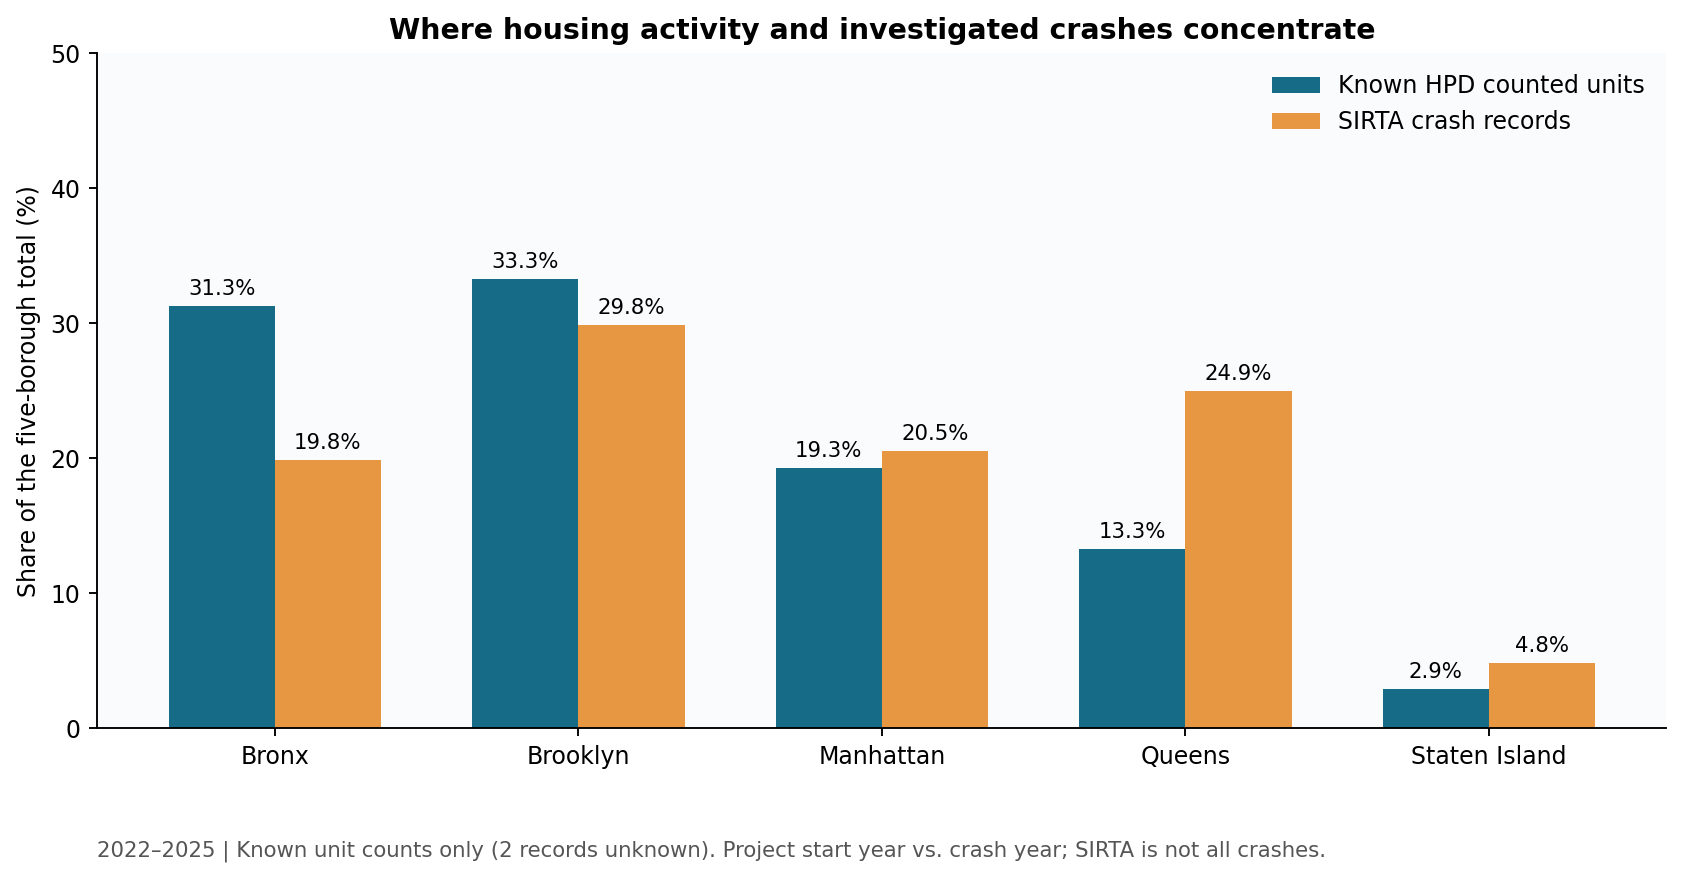

In [11]:
display(pd.read_csv(ROOT / "reports/M2_Q1_borough_shares.csv"))
display(Image(filename=str(ROOT / "charts/M2_Q1_borough_shares.png")))

**Answer:** Queens has 13.3% of known HPD counted units versus 24.9% of SIRTA records, a gap of 11.68 percentage points; the Bronx has 31.3% versus 19.8%. Housing and investigated-crash activity have different geographic distributions. **Limit:** incomplete known housing counts, source selection and population/road exposure differences prevent risk comparisons. **Use:** choose locations for coordinated investigation rather than labeling developments unsafe.

### M2 Q2 — Does housing composition align with crash severity?

**Question:** Are borough-years with a larger new-construction share of counted housing units associated with more recorded severely/fatally injured people per SIRTA crash record?

**Why this chart:** a bubble scatter compares two continuous measures; color identifies borough, year annotations identify repeated observations, bubble area reflects crash count. The severity measure counts people per record and can exceed one. Exclude the two incomplete housing cells rather than invent a share.

,borough,year,new_construction_share,severe_or_fatal_per_crash,crash_count
0,BRONX,2022,0.547679,1.091667,600
1,BRONX,2023,0.603214,1.076795,599
2,BRONX,2025,0.552125,1.090239,543
3,BROOKLYN,2022,0.831318,1.064407,885
4,BROOKLYN,2024,0.578725,1.067465,919
5,BROOKLYN,2025,0.599401,1.104664,879
6,MANHATTAN,2022,0.450838,1.078947,570
7,MANHATTAN,2023,0.213585,1.061256,653
8,MANHATTAN,2024,0.263971,1.054773,639
9,MANHATTAN,2025,0.234019,1.056314,586


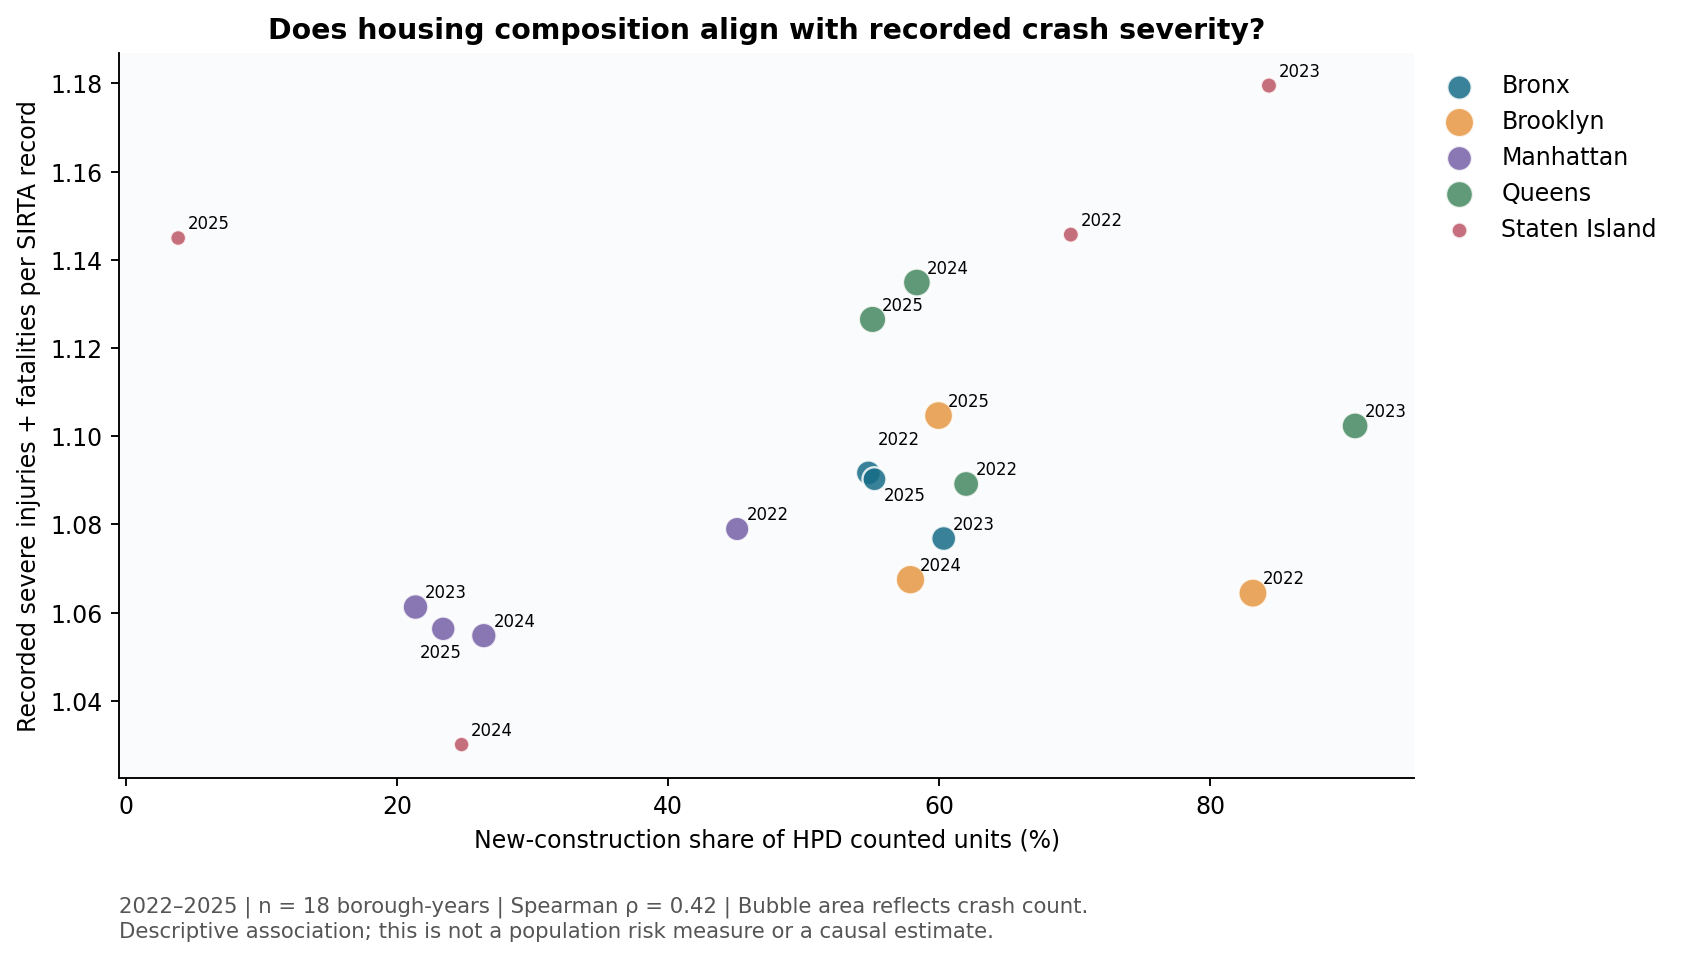

Complete borough-years and descriptive rank correlation: {'n_borough_years': 18, 'spearman_rho': 0.422}


In [12]:
display(pd.read_csv(ROOT / "reports/M2_Q2_composition.csv"))
display(Image(filename=str(ROOT / "charts/M2_Q2_composition_severity.png")))
print("Complete borough-years and descriptive rank correlation:", findings["M2_Q2"])

**Answer:** the 18 complete borough-years have a descriptive Spearman rho of 0.422. Borough-specific clusters and the small panel matter; this is not evidence that construction causes severe crashes. **Limit:** selected serious-crash investigations, unmeasured traffic/population, repeated observations and two excluded cells. **Use:** motivate better local exposure data and review before any intervention recommendation.

## 10. Member 3 research questions and visualizations

### M3 Q1 — Do activity trajectories move together?

**Question:** Do borough-level housing-unit and SIRTA-record trajectories move together between 2022 and 2025?

**Why this chart:** faceted lines index each metric to 2022=100 so counts with different units can be compared within borough. Panel y-scales vary; compare directions and changes within panels. Gaps deliberately mark incomplete housing totals instead of silently skipping missing contributing rows.

,borough,counted_units,crash_count
0,BRONX,57.252938,-9.500000
1,BROOKLYN,29.457364,-0.677966
2,MANHATTAN,96.838445,2.807018
3,QUEENS,120.116279,13.967311
4,STATEN ISLAND,8239.393939,-8.609272


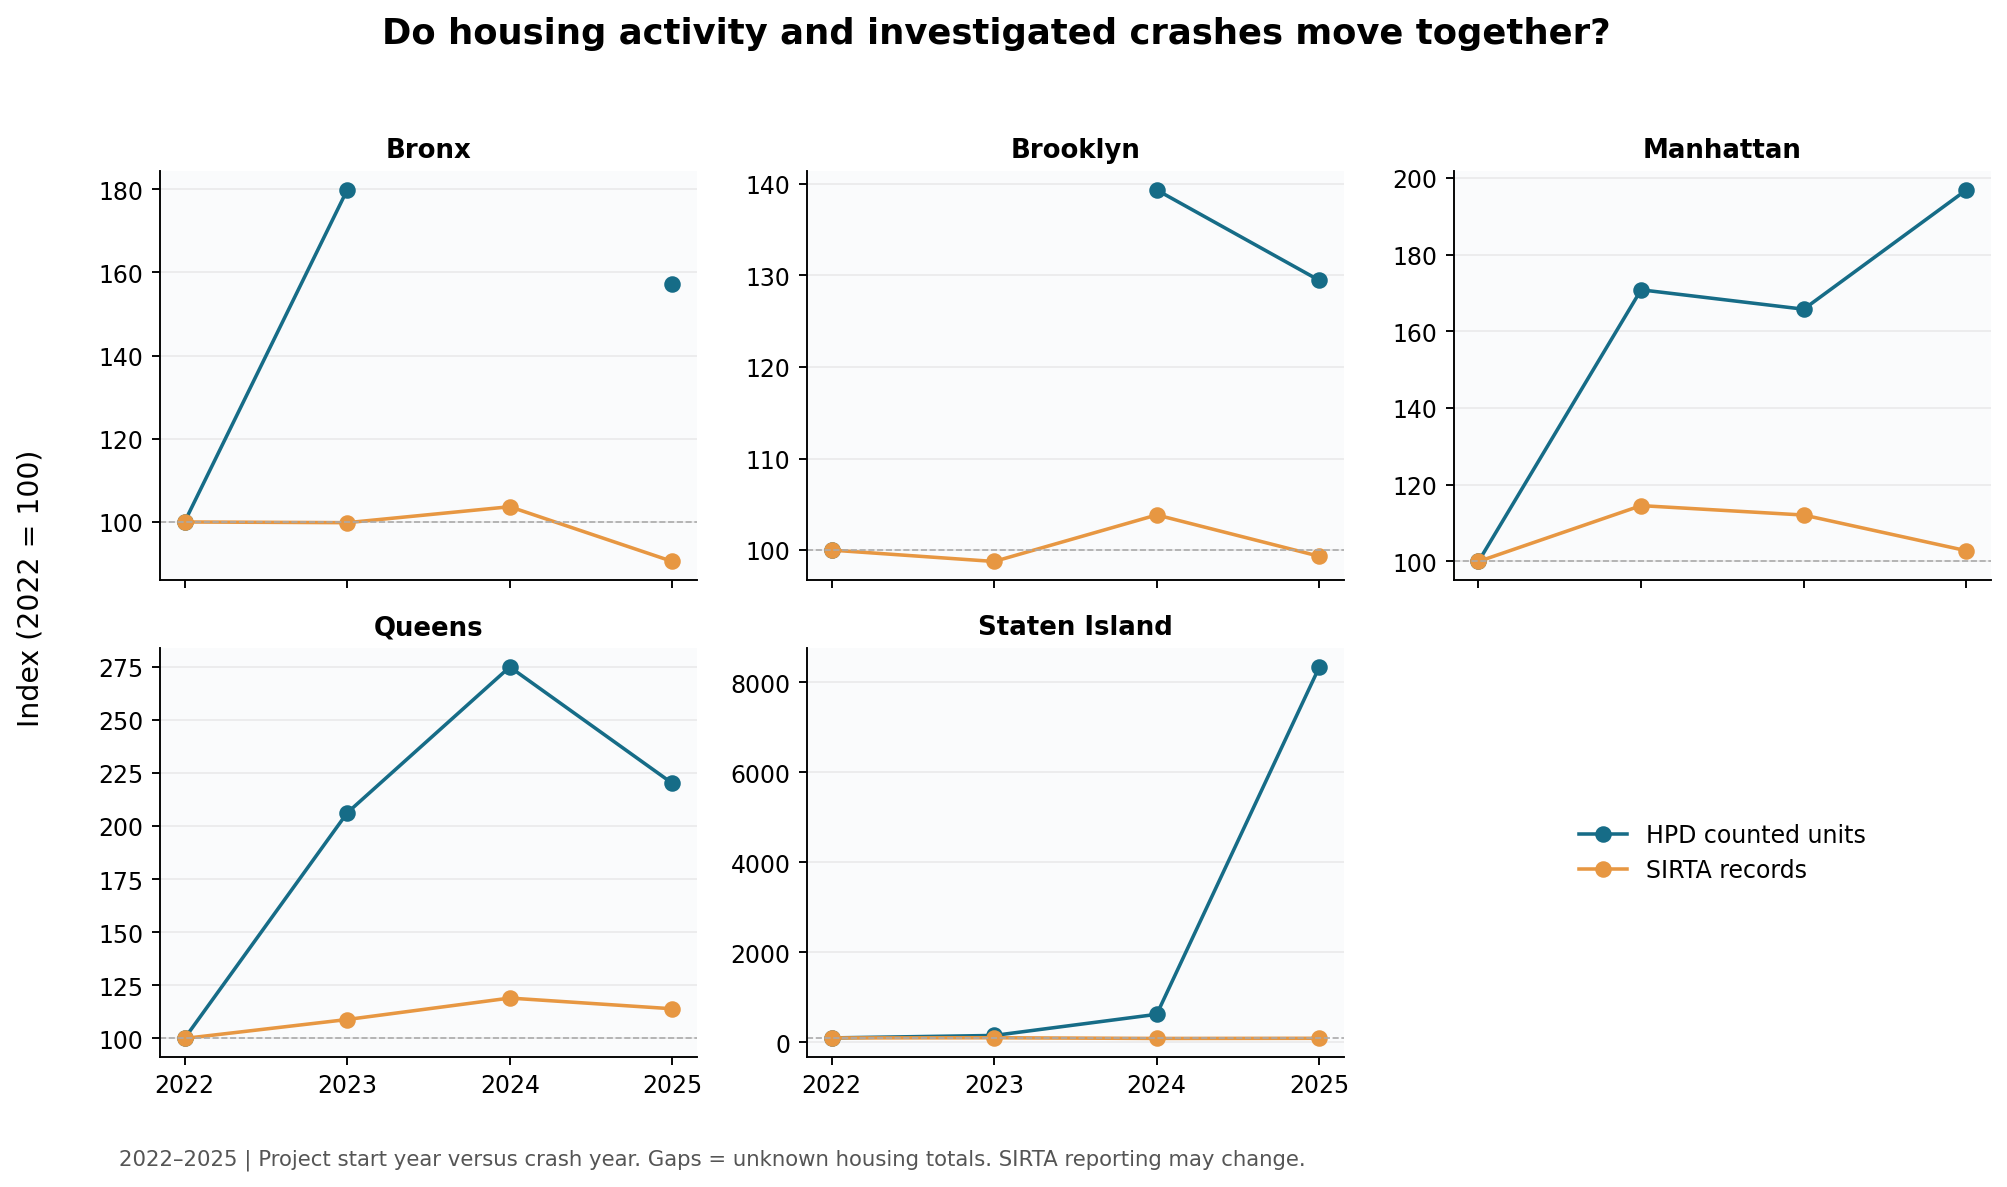

In [13]:
display(pd.read_csv(ROOT / "reports/M3_Q1_change_2022_2025.csv"))
display(Image(filename=str(ROOT / "charts/M3_Q1_indexed_trends.png")))

**Answer:** from 2022 to 2025 Queens' counted units rose 120.12%, versus 13.97% for SIRTA records; Manhattan's changes were 96.84% and 2.81%. The series do not show a uniform shared trajectory. Staten Island starts at only 33 counted units and reaches 2,752: its very large percentage change is a small-baseline effect, not evidence by itself of a citywide trend. **Limit:** project timing, preservation, investigation/reporting selection and four years of coarse data. **Use:** evaluate housing and safety planning together without assuming their annual counts should track proportionally.

### M3 Q2 — Is the pattern present within matched ZIP-years?

**Question:** Within matched 2023–2025 ZIP-years, are larger counted-unit volumes associated with more SIRTA records, and does the association differ by borough?

**Why this chart:** a log/log scatter of counts+1 shows the heavy-tailed values without deleting large properties; colors identify boroughs. Rank correlations are computed from the original counts (adding one/log axes do not change ranks). This is a secondary coverage-sensitive analysis. ZIPs with conflicting borough labels, unmatched source cells and incomplete housing totals are omitted explicitly.

,borough,n_zip_years,spearman_rho
0,BRONX,58,0.317136
1,BROOKLYN,94,-0.009338
2,MANHATTAN,75,0.226284
3,QUEENS,69,0.004758
4,STATEN ISLAND,10,0.506211


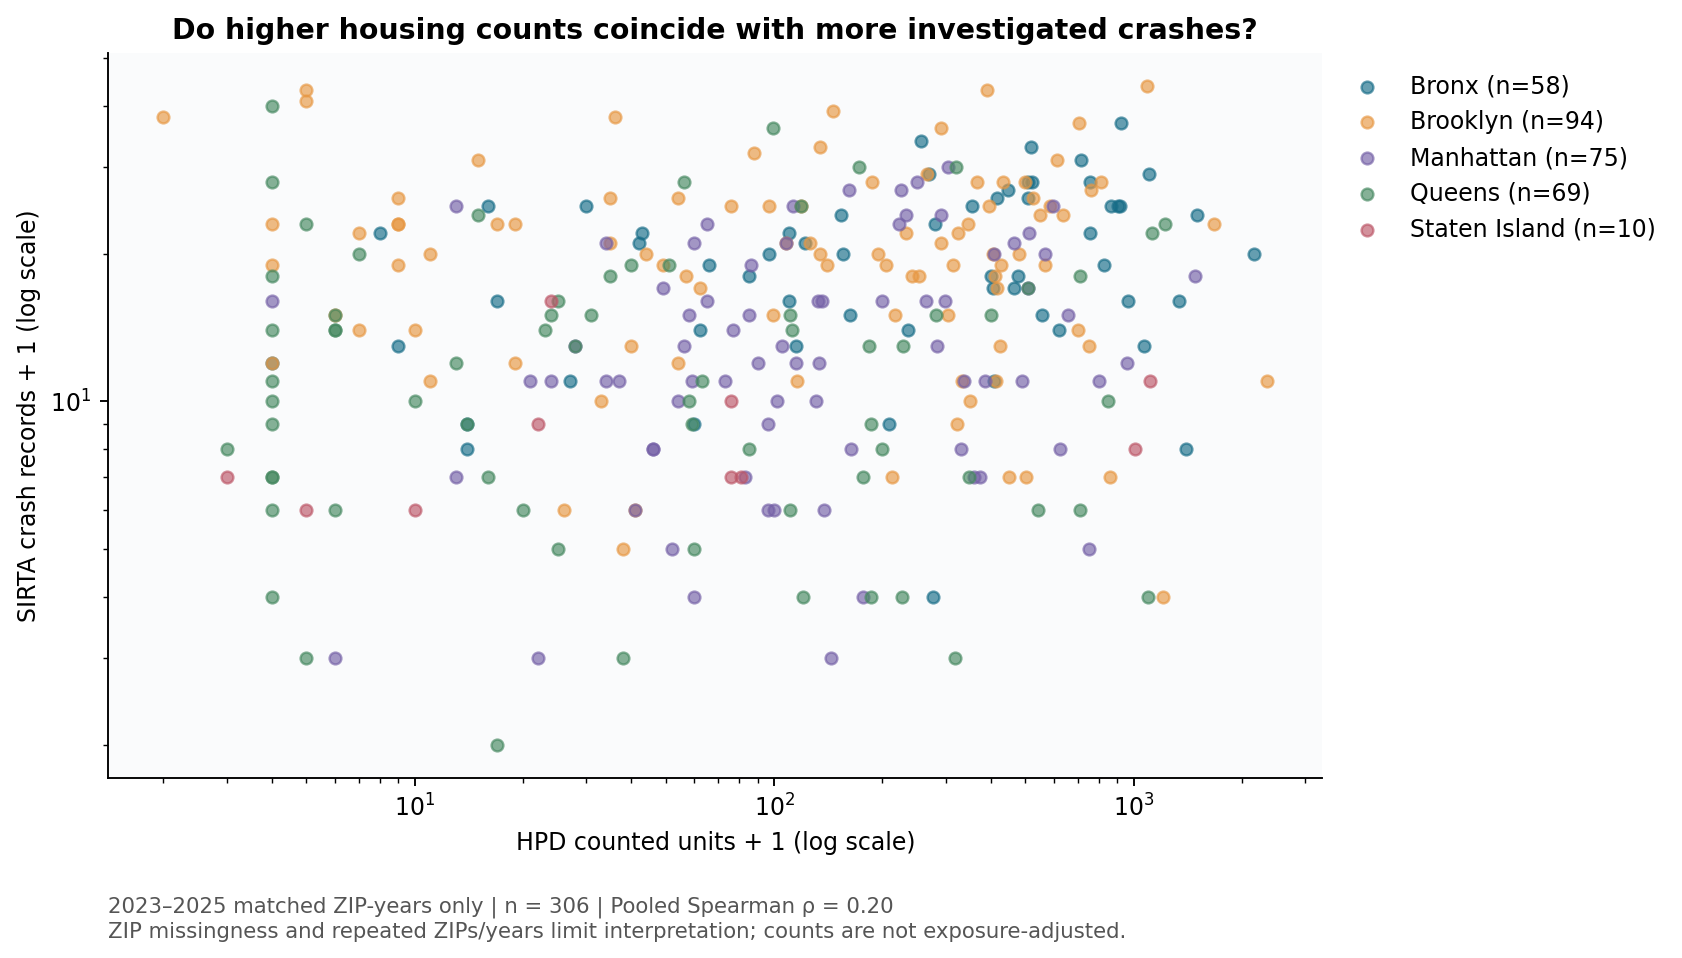

Matched complete cells: 306
Pooled descriptive Spearman rho: 0.196


In [14]:
display(pd.read_csv(ROOT / "reports/M3_Q2_within_borough_correlations.csv"))
display(Image(filename=str(ROOT / "charts/M3_Q2_zip_association.png")))
print("Matched complete cells:", findings["M3_Q2"]["n_matched_zip_years"])
print("Pooled descriptive Spearman rho:", findings["M3_Q2"]["pooled_spearman_rho"])

**Answer:** 306 complete matched ZIP-years have pooled rho=0.196, a weak positive relationship. Brooklyn (−0.009) and Queens (0.005) are close to zero, while the Bronx is 0.317. A pooled coefficient hides those differences. Staten Island has only ten cells. **Limit:** changing ZIP missingness, geography ambiguity, repeated ZIP/year observations, missing unobserved zero cells and unmeasured population/road exposure; no causal or statistical-significance claim is justified. **Use:** select better-defined local follow-up questions rather than conclude housing activity changes crash risk.

## 11. Validation and reproducibility

The next cell reruns acceptance checks against the bundled raw hashes and data. Transformation tests exercise invalid ZIPs, conflicting IDs, unknown severity, unmatched joins and duplicate-key rejection. Acceptance checks verify source dimensions/counts, row accounting, aggregate conservation, nonnegative measurements, one-to-one keys, preserved unknown join values and the full-year analysis window. No live download is needed.

In [15]:
result = validate(ROOT)
import unittest
suite = unittest.defaultTestLoader.discover(str(ROOT / "tests"), pattern="test_*.py")
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful()
display(result)

test_join_keeps_unknown_unmatched_and_rejects_multiplication (test_pipeline.PipelineTests) ... 

ok
test_transport_preserves_unknown_severity_and_quarantines_conflicts (test_pipeline.PipelineTests) ... 

ok
test_unknown_construction_type_does_not_become_zero_new_units (test_pipeline.PipelineTests) ... 

ok
test_zip_does_not_extract_digits_from_garbage (test_pipeline.PipelineTests) ... 

{
  "status": "PASS",
  "source_hashes_verified": true,
  "aggregation_conservation": true,
  "one_to_one_joins": true,
  "no_join_null_zero_imputation": true,
  "full_year_analysis_cells": 20,
  "primary_years": [
    2022,
    2023,
    2024,
    2025
  ],
  "transport_clean_rows": 13308,
  "housing_clean_rows": 9551
}


ok

----------------------------------------------------------------------
Ran 4 tests in 0.024s

OK


{'status': 'PASS',
 'source_hashes_verified': True,
 'aggregation_conservation': True,
 'one_to_one_joins': True,
 'no_join_null_zero_imputation': True,
 'full_year_analysis_cells': 20,
 'primary_years': [2022, 2023, 2024, 2025],
 'transport_clean_rows': 13308,
 'housing_clean_rows': 9551}

## 12. Contribution record, prompts and honest scope status

The table separates assigned ownership from actual preparation: Member 4 requested this work with AI assistance, so these files must not be presented as independently authored by absent members. Student IDs/names have not been supplied. Update these details truthfully before submission. Earlier Member 1 prompts were not supplied.

In [16]:
display(pd.read_csv(ROOT / "CONTRIBUTIONS.csv"))
display(Markdown((ROOT / "PROMPTS_USED.md").read_text()))

,assigned_role,student_name,student_id,scope,actual_work_disclosure,status
0,Member 1 Housing lead,Not supplied,Not supplied,Original source selection and supplied housing...,Supplied as Member 1 work; original preserved ...,Original preparation reviewed; two research qu...
1,Member 2 Transportation lead,Not supplied,Not supplied,Transport EDA cleaning aggregation M2-Q1 and M...,Prepared for Member 2 scope at Member 4's requ...,Complete in this handoff
2,Member 3 Integration and notebook lead,Not supplied,Not supplied,Join justification integration post-cleaning a...,Prepared for Member 3 scope at Member 4's requ...,Complete in this handoff; whole-team notebook ...
3,Member 4 Website lead,Not supplied,Not supplied,Requested completion of Member 2/3 scopes; web...,User identifies as Member 4; no deployment or ...,Website and own research scope pending


# Prompts and AI assistance disclosure

## User prompt used for this handoff (verbatim)

> hey chat this is my data enginnering project im in a team of 4 and im about to send you member 1's work and also what each member should do im member 4 however i want us to also do members 2 and 3's work since they are running late and its not prohibited to do other memebrs is work they will just get a deduction so i want us to first do member's 2 and 3 work and then well go from there before we start i want you thoroughly go over the description and members 1 work and then start doing here is what you need to do so act as senior data engineer and finish memeber 2 and 3's work and give me each one as seerate zip file

## Role requirements appended by the user

Member 1: Housing data lead
- Choose the housing dataset, with the feasibility check if it's outside the catalog.
- EDA and pre-integration cleaning for housing: missing values, outliers (IQR or domain rules), duplicates, and standardizing dates, strings and geographic IDs.
- Create the GitHub repo and own the README setup steps.
- 2 research questions + 2 charts.

Member 2: Transportation data lead
- Choose the transportation dataset (if it's very large, justify the filtered sample).
- The same EDA and pre-integration cleaning for the transport data.
- Aggregate to the common level (e.g., ZIP/borough × year).
- 2 research questions + 2 charts.

Member 3: Integration and notebook lead
- Decide the join key and granularity with Members 1 and 2, and document the justification.
- Perform the integration and the required post-integration cleaning: new nulls from the join, redundant columns, dtype mismatches.
- Assemble the final notebook (markdown narrative, dataset links, the prompts-used section) and keep the contribution table.
- 2 research questions + 2 charts.

Member 4: Website and deployment lead
- Build the Dash (or other) app skeleton: layout, dropdown filters, search mode (parse text like "Brooklyn 2022 new buildings" into filters), and the central **Generate Report** button wired to all charts.
- Deploy on Render or Vercel, test it, and write the README deployment section.
- Write the final submission email.
- 2 research questions + 2 charts.

## Assistance actually used

Codex/OpenAI assisted with reading the supplied requirements and original notebook, inspecting official source metadata, downloading full snapshots, selecting a coverage-aware join, writing the cleaning/integration code, research questions, charts, narrative, tests and packaging. No synthetic records or invented findings were used. The four findings were calculated from the included snapshots. No separate subagent prompts were used. Tool calls were used to inspect files, fetch source data and execute/validate code; they are implementation steps, not additional research questions.

The supplied Member 1 notebook contains no prompt log; its earlier prompts are unknown and must be added by its original contributor if applicable. Names/student IDs were not supplied. Do not replace this disclosure with a claim that Members 2/3 independently authored the work.


## 13. What this tells NYC, and what remains

HPD/DOT could use the distribution gaps and differing trajectories to select boroughs for coordinated local study. These sources cannot identify resident-level exposure, transit accessibility, crash causality or individual dangerous developments. Keep source definitions, coverage and missingness beside every chart.

The handoff supplies four cross-domain research questions/charts (two per requested role) plus EDA figures. A four-member submission requires eight. Member 1's missing two and Member 4's own two remain; so do the website's interactive plots, dropdown/search/Generate Report flow, story section, tested deployment, team IDs, GitHub publication and submission email. This assembled notebook is ready for those additions, not a claim the entire milestone is submitted.

For the website, load the main integrated table and select `analysis_eligible` as a boolean. Filter category tables within each domain, reaggregate and rejoin; category filters never establish a building-to-crash link. Recompute ratios from summed numerators/denominators. Preserve unknown values, and keep 2026 visibly partial. See `DATA_DICTIONARY.md` and `README.md` for the exact output contract.